# Hackatón 11: ¿Confiar, verificar o escalar? — Kaggle v2

**Equipo:** completar nombres. **Clase positiva:** buen crédito (`1 = bueno`,
`0 = malo`). **Objetivo:** maximizar HACS, con mejora estricta
$\Delta F1=F1_{colaborativo}-F1_{IA}>0.01$, más de un punto porcentual.
También se informa mejora relativa, sin confundirla con puntos porcentuales.

Comparamos cinco familias y elegimos **tres finalistas por HACS de validación**.
Se ajustan hiperparámetros y umbral de clasificación sólo con entrenamiento;
la política y la selección final usan validación. Prueba no decide nada.
Los humanos son simulados, junior 70% y senior 95%, exactamente como v1.

Se conservan las seis partes del PDF. La prueba de 200 casos ya se inspeccionó en
v1: esta v2 no es un holdout externo nuevo. Cambiar la clase positiva cambia el
valor de F1; comparar con v1 requiere recodificar sus predicciones guardadas.

**Fuente:** Hofmann (1994), [UCI Statlog German Credit](https://archive.ics.uci.edu/dataset/144/statlog+german+credit+data),
[DOI 10.24432/C5NC77](https://doi.org/10.24432/C5NC77), CC BY 4.0.
Guía: `Sem13_Hackaton11.pdf` y diccionario `data/readme.md`.

### Entorno y reproducibilidad

Kaggle proporciona los cinco clasificadores y SHAP. La sesión solicita Tesla T4;
el entrenamiento usa CPU, suficiente para 1,000 filas y reproducible. Se registran
versiones, hardware, hash del archivo, particiones, CV, políticas y resultados.

In [1]:
import os, sys, json, hashlib, platform, subprocess, time
from pathlib import Path
import importlib.metadata as metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import mannwhitneyu
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
    RocCurveDisplay, brier_score_loss)
import joblib
import shap
plt.rcParams.update({"figure.figsize": (9, 4.5), "font.size": 11,
                     "axes.spines.top": False, "axes.spines.right": False})
COLORS = {"IA": "#28689a", "Humano–IA": "#b47722", "Junior": "#7d8050", "Senior": "#a34f80"}
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_predict
from sklearn.base import clone

### Configuración del experimento

La semilla de prueba y la réplica reportada se fijan antes de entrenar. No se
buscan semillas que favorezcan la mejora. Guardamos 500 simulaciones de validación
y 1,000 de prueba; el intervalo Monte Carlo refleja únicamente incertidumbre humana.

In [2]:
MODE, SEED = "kaggle", 42
N_VAL_SIM, N_TEST_SIM = 500, 1000
JUNIOR_ACCURACY, SENIOR_ACCURACY = 0.70, 0.95
MIN_GAIN = 0.01
GROUP = "Equipo por completar"
DATA = next(p.parent for p in Path("/kaggle/input").rglob("german.data"))
OUT = Path("/kaggle/working")
OUT.mkdir(parents=True,exist_ok=True)
versions = {p:metadata.version(p) for p in ["numpy","pandas","scikit-learn","scipy","matplotlib","shap","xgboost","lightgbm","catboost"]}
summary = {"status":"running","stage":"setup","experiment":"v2","positive_class":"good_credit",
           "label_mapping":{"0":"bad_credit","1":"good_credit"},"seed":SEED,
           "python":sys.version,"versions":versions,"human_simulation_only":True,
           "minimum_absolute_f1_gain_strict":MIN_GAIN,"test_seen_in_v1":True}
def checkpoint(stage,**values):
    summary.update(stage=stage,**values)
    (OUT/"run_summary.json").write_text(json.dumps(summary,indent=2,ensure_ascii=False),encoding="utf-8")
def savefig(name):
    plt.tight_layout()
    plt.savefig(OUT/name,dpi=150,bbox_inches="tight")
    plt.show()
    plt.close()
gpu = subprocess.run(["nvidia-smi","--query-gpu=name","--format=csv,noheader"],capture_output=True,text=True).stdout.strip()
checkpoint("setup",hardware=gpu,estimator_device="CPU")
print("v2 · positivo = buen crédito | Hardware:",gpu)

v2 · positivo = buen crédito | Hardware: Tesla T4
Tesla T4


## Parte 1 — Comprensión del problema y exploración (10%)

### Actividad 1.1 — Contexto y coste de equivocarse

Aprobar a un cliente malo puede causar pérdida de capital; rechazar a un buen
cliente pierde negocio y puede perjudicarlo injustamente. El README asigna coste
cinco al primer error y uno al segundo. Con **positivo = bueno**, FP significa
aprobar a un cliente malo y FN rechazar a uno bueno: **coste = 5 FP + FN**.

Medimos F1 binario de **buen crédito**, según la solicitud de esta v2. F1 de mal
crédito y F1 macro quedan como métricas complementarias; ni el cambio de etiqueta
ni un HACS mayor demuestran por sí solos menor riesgo financiero o mayor equidad.

### Actividad 1.2 — Datos y diccionario

Usamos `german.data`, 20 atributos y 1,000 filas. La representación numérica
alternativa no añade observaciones. A65/A124 son categorías del diccionario,
no celdas nulas. Conservamos los atributos personales para reproducir el ejercicio;
no asumimos que ello permita un despliegue bancario.

In [3]:
FEATURES = ["checking", "duration", "credit_history", "purpose", "amount", "savings",
            "employment", "installment_rate", "personal_status_sex", "guarantors",
            "residence_since", "property", "age", "other_plans", "housing",
            "existing_credits", "job", "dependents", "telephone", "foreign_worker"]
NUM = ["duration", "amount", "installment_rate", "residence_since", "age", "existing_credits", "dependents"]
CAT = [c for c in FEATURES if c not in NUM]
df = pd.read_csv(DATA / "german.data", sep=r"\s+", header=None, names=FEATURES + ["original_class"])
assert df.shape == (1000, 21)
assert set(df.original_class) == {1, 2}
X = df[FEATURES].copy()
y = (df.original_class == 1).astype(int).to_numpy()
assert np.bincount(y).tolist() == [300, 700]
digest = hashlib.sha256((DATA / "german.data").read_bytes()).hexdigest()
quality = {"rows": len(df), "features": len(FEATURES), "numeric": len(NUM), "categorical": len(CAT),
           "missing_cells": int(df.isna().sum().sum()), "duplicate_rows": int(df.duplicated().sum()),
           "sha256": digest, "class_0_bad": int(sum(y == 0)), "class_1_good": int(sum(y == 1))}
checkpoint("data", dataset=quality)
display(pd.Series(quality, name="Valor").to_frame())
display(df.head(4))
display(df[NUM].describe().round(2))
display(pd.DataFrame({"variable": CAT, "categorias": [df[c].nunique() for c in CAT]}))

,Valor
rows,1000
features,20
numeric,7
categorical,13
missing_cells,0
duplicate_rows,0
sha256,b21f3d81db8071257d5ff1deaeba1fd4303b62712e6fcc...
class_0_bad,300
class_1_good,700


,checking,duration,credit_history,purpose,amount,savings,employment,installment_rate,personal_status_sex,guarantors,...,property,age,other_plans,housing,existing_credits,job,dependents,telephone,foreign_worker,original_class
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,...,A121,67,A143,A152,2,A173,1,A192,A201,1
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,...,A121,22,A143,A152,1,A173,1,A191,A201,2
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,...,A121,49,A143,A152,1,A172,2,A191,A201,1
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,...,A122,45,A143,A153,1,A173,2,A191,A201,1


,duration,amount,installment_rate,residence_since,age,existing_credits,dependents
count,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00,1000.00
mean,20.90,3271.26,2.97,2.84,35.55,1.41,1.16
std,12.06,2822.74,1.12,1.10,11.38,0.58,0.36
min,4.00,250.00,1.00,1.00,19.00,1.00,1.00
25%,12.00,1365.50,2.00,2.00,27.00,1.00,1.00
50%,18.00,2319.50,3.00,3.00,33.00,1.00,1.00
75%,24.00,3972.25,4.00,4.00,42.00,2.00,1.00
max,72.00,18424.00,4.00,4.00,75.00,4.00,2.00


,variable,categorias
0,checking,4
1,credit_history,5
2,purpose,10
3,savings,5
4,employment,5
5,personal_status_sex,4
6,guarantors,3
7,property,4
8,other_plans,3
9,housing,3


### Exploración gráfica y correlaciones

Edad, duración y balance de clases describen la población. Las correlaciones son
Pearson para variables numéricas y la etiqueta de buen crédito; no implican causalidad.
Este EDA no interviene en la selección de atributos, umbrales ni modelos. El conjunto
de prueba se mantiene fuera de toda decisión de ajuste.

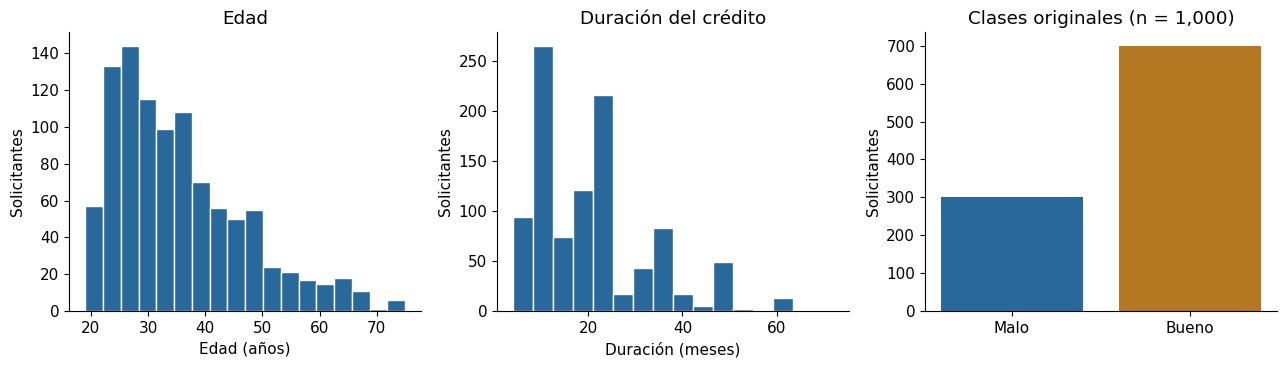

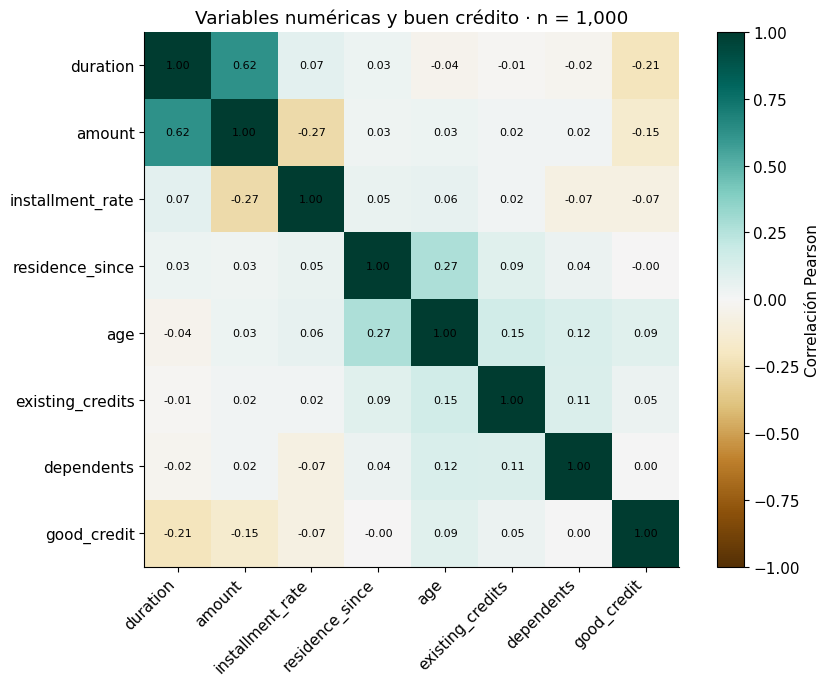

,good_credit
duration,-0.215
amount,-0.155
age,0.091
installment_rate,-0.072
existing_credits,0.046
dependents,0.003
residence_since,-0.003


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8))
axes[0].hist(df.age, bins=18, color=COLORS["IA"], edgecolor="white")
axes[0].set(xlabel="Edad (años)", ylabel="Solicitantes", title="Edad")
axes[1].hist(df.duration, bins=16, color=COLORS["IA"], edgecolor="white")
axes[1].set(xlabel="Duración (meses)", ylabel="Solicitantes", title="Duración del crédito")
axes[2].bar(["Malo", "Bueno"], np.bincount(y), color=[COLORS["IA"], COLORS["Humano–IA"]])
axes[2].set(ylabel="Solicitantes", title="Clases originales (n = 1,000)")
savefig("01_exploracion.png")
corr = df[NUM].assign(good_credit=y).corr()
corr.to_csv(OUT / "correlaciones.csv")
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(corr, cmap="BrBG", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right")
ax.set_yticks(range(len(corr)), corr.index)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i,j]:.2f}", ha="center", va="center", fontsize=8)
fig.colorbar(im, ax=ax, label="Correlación Pearson")
ax.set_title("Variables numéricas y buen crédito · n = 1,000")
savefig("02_correlaciones.png")
display(corr["good_credit"].drop("good_credit").sort_values(key=abs, ascending=False).to_frame().round(3))

## Parte 2 — Desarrollo del modelo base (20%)

### Actividad 2.1 — Particiones y preprocesamiento

Conservamos exactamente las filas de v1: 600 entrenamiento, 200 validación y
200 prueba. Estratificamos usando `1-y`, la codificación de v1, para reproducir
sus índices después de invertir la clase positiva. La proporción es 70% buenos.

Imputación preventiva, one-hot y escalamiento se ajustan sólo con entrenamiento.
Durante CV, el **pipeline completo** se ajusta de nuevo dentro de cada fold;
no preprocesamos los folds con estadísticas del fold que se evalúa.

In [5]:
idx_trainval, idx_test = train_test_split(np.arange(len(df)), test_size=0.2, stratify=1-y, random_state=SEED)
idx_train, idx_val = train_test_split(idx_trainval, test_size=0.25, stratify=1-y[idx_trainval], random_state=SEED)
assert not (set(idx_train) & set(idx_val) or set(idx_train) & set(idx_test) or set(idx_val) & set(idx_test))
split = pd.DataFrame({"row_id": np.arange(len(df)), "split": "train", "y": y})
split.loc[idx_val, "split"] = "validation"
split.loc[idx_test, "split"] = "test"
split.to_csv(OUT / "particiones.csv", index=False)
display(pd.crosstab(split.split, split.y).rename(columns={0: "Malo", 1: "Bueno"}))
pre = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), NUM),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CAT)])
Ztrain = pre.fit_transform(X.iloc[idx_train])
Zval, Ztest = pre.transform(X.iloc[idx_val]), pre.transform(X.iloc[idx_test])
yt, yv, ye = y[idx_train], y[idx_val], y[idx_test]
names = pre.get_feature_names_out()
print("Matrices transformadas:", Ztrain.shape, Zval.shape, Ztest.shape)

y,Malo,Bueno
split,,
test,60,140
train,180,420
validation,60,140


Matrices transformadas: (600, 61) (200, 61) (200, 61)


### Actividad 2.2 — Candidatos y búsqueda de hiperparámetros

Evaluamos XGBoost, LightGBM, CatBoost, Random Forest y Logistic Regression.
GridSearchCV usa cinco folds estratificados **sólo en entrenamiento**, puntuando
F1 de buen crédito. Cada familia aporta una configuración final. No se aplica
SMOTE, ni se cambian las accuracies humanas. Las curvas ROC usan P(buen crédito).

In [6]:
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
candidates = {
    "XGBoost": (XGBClassifier(learning_rate=0.05,subsample=0.9,colsample_bytree=0.9,
        reg_lambda=3,eval_metric="logloss",random_state=SEED,n_jobs=2),
        {"model__n_estimators":[120,260],"model__max_depth":[2,3]}),
    "LightGBM": (LGBMClassifier(learning_rate=0.05,min_child_samples=20,reg_lambda=3,
        verbosity=-1,random_state=SEED,n_jobs=2),
        {"model__n_estimators":[120,260],"model__num_leaves":[5,9]}),
    "CatBoost": (CatBoostClassifier(learning_rate=0.05,l2_leaf_reg=5,loss_function="Logloss",
        random_seed=SEED,verbose=False,allow_writing_files=False,thread_count=2),
        {"model__iterations":[150,300],"model__depth":[3,5]}),
    "Random Forest": (RandomForestClassifier(n_estimators=250,random_state=SEED,n_jobs=2),
        {"model__max_depth":[5,8,None],"model__min_samples_leaf":[2,5]}),
    "Logistic Regression": (LogisticRegression(max_iter=2000,solver="lbfgs",random_state=SEED),
        {"model__C":[0.05,0.2,1,5],"model__class_weight":[None,"balanced"]})}
cv = StratifiedKFold(n_splits=5,shuffle=True,random_state=2026)
cv_folds = np.full(len(idx_train),-1,dtype=int)
for fold,(_,held) in enumerate(cv.split(X.iloc[idx_train],yt)):
    cv_folds[held] = fold
pd.DataFrame({"row_id":idx_train,"fold":cv_folds,"y_good":yt}).to_csv(OUT/"folds_entrenamiento.csv",index=False)

### Métricas, entropía y simulación: funciones auditables

F1 principal = `2 TP / (2 TP + FP + FN)`, positivo bueno. La entropía se calcula
con logaritmo natural y alcanza ln(2) en p=0.5. El enrutador sólo ve entropía;
las etiquetas reales se usan exclusivamente para evaluar y simular respuestas.
Junior/senior tienen errores Bernoulli, como v1, con generadores continuos por caso.

In [7]:
def metrics(truth, pred, probability=None):
    tn, fp, fn, tp = confusion_matrix(truth, pred, labels=[0,1]).ravel()
    return {"Accuracy": accuracy_score(truth,pred), "Precision": precision_score(truth,pred,zero_division=0),
            "Recall": recall_score(truth,pred,zero_division=0), "F1": f1_score(truth,pred,zero_division=0),
            "F1_bad": f1_score(truth,pred,pos_label=0,zero_division=0),
            "F1_macro": f1_score(truth,pred,average="macro",zero_division=0),
            "ROC_AUC": roc_auc_score(truth,probability) if probability is not None else np.nan,
            "Coste": int(5*fp + fn), "Coste_por_caso": float((5*fp+fn)/len(truth)),
            "TN":int(tn), "FP":int(fp), "FN":int(fn), "TP":int(tp)}

def entropy(probability):
    p = np.clip(np.asarray(probability,dtype=float),1e-12,1-1e-12)
    return -p*np.log(p) - (1-p)*np.log(1-p)
assert np.isclose(entropy([0.5])[0],np.log(2))
assert entropy([0,1]).max() < 1e-8
assert np.allclose(entropy([0.2,0.8]), entropy([0.8,0.2]))

def simulate_analysts(truth, repetitions, seed):
    rng = np.random.default_rng(seed)
    u = rng.random((2,repetitions,len(truth)))
    return (np.where(u[0] < JUNIOR_ACCURACY, truth, 1-truth),
            np.where(u[1] < SENIOR_ACCURACY, truth, 1-truth))
def route(uncertainty,a,b):
    if not 0 <= a <= b:
        raise ValueError("Los umbrales requieren 0 <= A <= B")
    return np.where(uncertainty<a,"IA",np.where(uncertainty<b,"Junior","Senior"))
def collaborate(ai,makers,junior,senior):
    return np.where(makers=="IA",ai,np.where(makers=="Junior",junior,senior))
def f1_many(truth,predictions):
    tp = np.sum((predictions==1)&(truth==1),axis=-1)
    fp = np.sum((predictions==1)&(truth==0),axis=-1)
    fn = np.sum((predictions==0)&(truth==1),axis=-1)
    return np.divide(2*tp,2*tp+fp+fn,out=np.zeros_like(tp,dtype=float),where=(2*tp+fp+fn)>0)
# Controles con resultados conocidos y extremos de la política.
assert np.isclose(f1_many(np.array([1,1,0,0]),np.array([[1,0,1,0]]))[0],0.5)
assert np.all(route(np.array([0.1,0.6]),np.log(2)+1e-8,np.log(2)+1e-8)=="IA")
assert np.all(route(np.array([0.1,0.6]),0,0)=="Senior")
jcheck,scheck = simulate_analysts(np.tile([0,1],5000),10,10)
assert abs(np.mean(jcheck==np.tile([0,1],5000))-0.70)<0.01
assert abs(np.mean(scheck==np.tile([0,1],5000))-0.95)<0.01

### Ajuste y umbral binario de cada familia

Tras seleccionar hiperparámetros con CV, calculamos probabilidades out-of-fold
de entrenamiento para elegir el umbral que maximiza F1 de **IA sola**. Esto
fortalece el baseline y evita fabricar mejora usando un umbral arbitrariamente
malo. La puntuación OOF participa en el ajuste y no es la evaluación final.
Guardamos los folds y las probabilidades para auditarlo.

In [8]:
fitted,models,val_prob,test_prob,thresholds_cls = {},{},{},{},{}
training_rows,cv_tables,oof_rows = [],[],[]
for name,(estimator,grid) in candidates.items():
    start = time.perf_counter()
    pipe = Pipeline([("pre",clone(pre)),("model",estimator)])
    search_cv = GridSearchCV(pipe,grid,scoring="f1",cv=cv,refit=True,n_jobs=1,error_score="raise")
    search_cv.fit(X.iloc[idx_train],yt)
    fitted[name] = search_cv.best_estimator_
    models[name] = fitted[name].named_steps["model"]
    oof = cross_val_predict(clone(fitted[name]),X.iloc[idx_train],yt,cv=cv,method="predict_proba",n_jobs=1)[:,1]
    threshold_grid = np.unique(np.r_[np.linspace(0.1,0.9,81),0.5])
    threshold_f1 = np.array([f1_score(yt,oof>=t) for t in threshold_grid])
    # Ante un empate, el umbral más cercano a 0.5 evita extremos innecesarios.
    optimum = threshold_f1.max()
    tied = threshold_grid[np.isclose(threshold_f1,optimum,rtol=0,atol=1e-12)]
    tau = float(tied[np.argmin(abs(tied-0.5))])
    thresholds_cls[name] = tau
    val_prob[name] = fitted[name].predict_proba(X.iloc[idx_val])[:,1]
    training_rows.append({"Modelo":name,"Threshold":tau,"CV_F1_good":float(search_cv.best_score_),
        "OOF_F1_good":float(optimum),**metrics(yv,val_prob[name]>=tau,val_prob[name]),
        "Brier":brier_score_loss(yv,val_prob[name]),"Segundos":time.perf_counter()-start,
        "Parametros":json.dumps(search_cv.best_params_,sort_keys=True)})
    table = pd.DataFrame(search_cv.cv_results_)
    table["Modelo"] = name
    cv_tables.append(table[["Modelo","params","mean_test_score","std_test_score","rank_test_score"]])
    oof_rows.append(pd.DataFrame({"Modelo":name,"row_id":idx_train,"fold":cv_folds,"y_good":yt,"p_good_oof":oof}))
    print(name,"| CV F1:",round(search_cv.best_score_,4),"| umbral:",tau)
    pd.DataFrame(training_rows).to_csv(OUT/"modelos_validacion.csv",index=False)
    checkpoint("training",families_finished=len(training_rows))
validation = pd.DataFrame(training_rows)
pd.concat(cv_tables,ignore_index=True).to_csv(OUT/"grid_search_entrenamiento.csv",index=False)
pd.concat(oof_rows,ignore_index=True).to_csv(OUT/"probabilidades_oof_entrenamiento.csv",index=False)
display(validation[["Modelo","Threshold","CV_F1_good","F1","F1_bad","ROC_AUC"]].round(4))

XGBoost | CV F1: 0.8458 | umbral: 0.48


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

LightGBM | CV F1: 0.8414 | umbral: 0.32
CatBoost | CV F1: 0.8464 | umbral: 0.41000000000000003
Random Forest | CV F1: 0.8521 | umbral: 0.47
Logistic Regression | CV F1: 0.8439 | umbral: 0.48


,Modelo,Threshold,CV_F1_good,F1,F1_bad,ROC_AUC
0,XGBoost,0.48,0.8458,0.8106,0.4242,0.7240
1,LightGBM,0.32,0.8414,0.8418,0.4048,0.7245
2,CatBoost,0.41,0.8464,0.8129,0.3556,0.7270
3,Random Forest,0.47,0.8521,0.8254,0.3529,0.7349
4,Logistic Regression,0.48,0.8439,0.8158,0.4167,0.7210


### Selección conjunta de tres modelos y políticas — validación

Para cada familia, probamos A/B en cuantiles de entropía de validación.
$H<A$: IA; $A\leq H<B$: junior; $H\geq B$: senior. Permitir A=B evita forzar
junior cuando no aporta: HACS penaliza igual una revisión junior que una senior.

Elegimos máximo HACS medio entre políticas con **mejora media ≥0.02** y
**percentil 10 de mejora >0.01**, en 500 réplicas. Este margen busca que el requisito
estricto >0.01 no dependa de una respuesta humana afortunada; no lo garantiza
en prueba. Después seleccionamos las tres familias elegibles con mayor HACS.
Se guardan todas las políticas y el orden antes de calcular predicciones de prueba.

In [9]:
jval,sval = simulate_analysts(yv,N_VAL_SIM,seed=1001)
policies,grid_rows = {},[]
for name,prob in val_prob.items():
    u,ai = entropy(prob),(prob>=thresholds_cls[name]).astype(int)
    baseline = f1_score(yv,ai)
    cuts = np.unique(np.r_[0,np.quantile(u,np.linspace(0.05,0.995,32)),np.log(2)+1e-8])
    rows = []
    for a in cuts:
        for b in cuts[cuts>=a]:
            makers = route(u,a,b)
            fs = f1_many(yv,collaborate(ai,makers,jval,sval))
            delta = fs-baseline
            coverage = float(np.mean(makers=="IA"))
            row = {"Modelo":name,"Threshold":thresholds_cls[name],"A":float(a),"B":float(b),
                "F1_IA":float(baseline),"F1_colab_mean":float(fs.mean()),"Mejora":float(delta.mean()),
                "Delta_p10":float(np.quantile(delta,0.1)),"Prob_mejora_mayor_1pp":float(np.mean(delta>MIN_GAIN)),
                "Coverage":coverage,"Efficiency":coverage,"HACS":float(.6*fs.mean()+.4*coverage),
                "Junior":int(sum(makers=="Junior")),"Senior":int(sum(makers=="Senior"))}
            row["Elegible_validacion"] = row["Mejora"]>=0.02 and row["Delta_p10"]>MIN_GAIN
            rows.append(row)
    grid = pd.DataFrame(rows)
    feasible = grid[grid.Elegible_validacion]
    choice = (feasible if len(feasible) else grid).sort_values(["HACS","Coverage"],ascending=False).iloc[0].to_dict()
    policies[name] = choice
    grid_rows.extend(rows)
search = pd.DataFrame(grid_rows)
search.to_csv(OUT/"busqueda_umbrales_validacion.csv",index=False)
policy_table = pd.DataFrame(policies.values()).sort_values(["Elegible_validacion","HACS"],ascending=False)
eligible = policy_table[policy_table.Elegible_validacion]
assert len(eligible)>=3,"No hay tres familias elegibles; detener antes de evaluar prueba."
finalist_names = eligible.head(3).Modelo.tolist()
best_name = finalist_names[0]
best_model = models[best_name]
chosen = policies[best_name]
policy_table["Finalista"] = policy_table.Modelo.isin(finalist_names)
policy_table.to_csv(OUT/"seleccion_modelos_validacion.csv",index=False)
policy_table.to_csv(OUT/"politicas_congeladas.csv",index=False)
(OUT/"politicas_congeladas.json").write_text(json.dumps(policies,indent=2),encoding="utf-8")
(OUT/"finalistas_congelados.json").write_text(json.dumps({"selection_split":"validation","criterion":"mean_HACS",
    "finalists":finalist_names,"selected":best_name,"classification_thresholds":thresholds_cls},indent=2),encoding="utf-8")
pre = fitted[best_name].named_steps["pre"]
Ztrain,Zval,Ztest = pre.transform(X.iloc[idx_train]),pre.transform(X.iloc[idx_val]),pre.transform(X.iloc[idx_test])
names = pre.get_feature_names_out()
for name in finalist_names:
    assert np.array_equal(fitted[name].named_steps["pre"].get_feature_names_out(),names)
    assert np.allclose(fitted[name].named_steps["pre"].transform(X.iloc[idx_train]),Ztrain)
checkpoint("finalists_frozen",selected_model=best_name,finalists=finalist_names,policy=chosen,
           validation_repetitions=N_VAL_SIM)
display(policy_table[["Modelo","F1_IA","F1_colab_mean","Mejora","Delta_p10","Coverage","HACS","Finalista"]].round(4))
print("Tres finalistas congelados:",finalist_names,"| Defendido:",best_name)

,Modelo,F1_IA,F1_colab_mean,Mejora,Delta_p10,Coverage,HACS,Finalista
3,Random Forest,0.8254,0.8493,0.0239,0.0195,0.90,0.8696,True
2,CatBoost,0.8129,0.8369,0.0240,0.0193,0.90,0.8621,True
0,XGBoost,0.8106,0.8431,0.0325,0.0266,0.87,0.8539,True
4,Logistic Regression,0.8158,0.8426,0.0268,0.0219,0.87,0.8535,False
1,LightGBM,0.8418,0.8687,0.0269,0.0201,0.81,0.8452,False


Tres finalistas congelados: ['Random Forest', 'CatBoost', 'XGBoost'] | Defendido: Random Forest


## Parte 3 — Cuantificación de incertidumbre (20%)

### Actividades 3.1 y 3.2 — Probabilidades y entropía

Usamos $p=P(buen\ crédito\mid x)$ y $H=-p\ln(p)-(1-p)\ln(1-p)$, en nats.
El máximo sigue siendo ln(2), aunque el umbral binario aprendido sea distinto
de 0.5. Entropía y umbral de clasificación son conceptos diferentes. La primera
describe la distribución predictiva; el segundo convierte probabilidades en clase.

In [10]:
pv = val_prob[best_name]
uv = entropy(pv)
uncertainty_val = pd.DataFrame({"row_id":idx_val,"y":yv,"p_good":pv,"entropy":uv,"correct":(pv>=thresholds_cls[best_name])==yv})
uncertainty_val.to_csv(OUT / "incertidumbre_validacion.csv",index=False)
display(uncertainty_val.head().round(4))

,row_id,y,p_good,entropy,correct
0,254,1,0.8247,0.4643,True
1,557,0,0.6826,0.6249,False
2,185,1,0.9751,0.1164,True
3,654,1,0.9819,0.0906,True
4,646,1,0.3877,0.6677,False


### Actividades 3.3 y 3.4 — ¿La incertidumbre identifica errores?

Mostramos histograma, boxplot aciertos/errores y accuracy por intervalos de
entropía. Los intervalos vacíos no se dibujan como accuracy cero. Comparamos
medias y usamos Mann–Whitney bilateral como análisis exploratorio; AUC de
detección de error > 0.5 indica que mayor entropía tiende a identificar errores.
La prueba estadística no demuestra calibración ni determina sola el escalamiento.

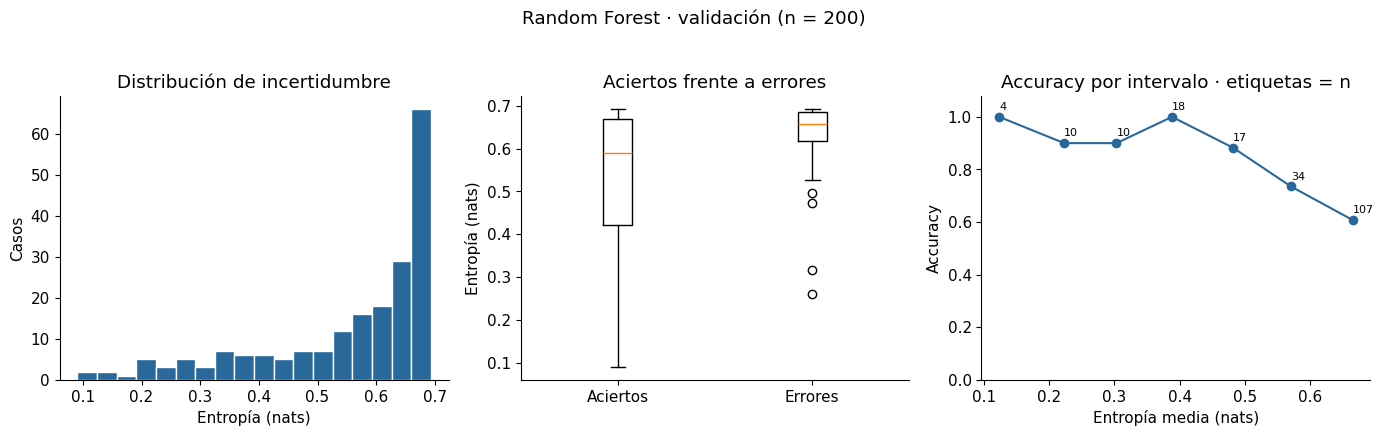

,Valor
split,validación
mean_correct,0.529517
mean_error,0.631207
mann_whitney_p,0.000013
error_detection_auc,0.699812


In [11]:
def uncertainty_analysis(prob, truth, split_name, filename):
    u = entropy(prob)
    correct = (prob>=thresholds_cls[best_name])==truth
    fig, axes = plt.subplots(1,3,figsize=(14,4.2))
    axes[0].hist(u,bins=18,color=COLORS["IA"],edgecolor="white")
    axes[0].set(xlabel="Entropía (nats)",ylabel="Casos",title="Distribución de incertidumbre")
    axes[1].boxplot([u[correct],u[~correct]],tick_labels=["Aciertos","Errores"])
    axes[1].set(ylabel="Entropía (nats)",title="Aciertos frente a errores")
    bins = pd.cut(u,np.linspace(0,np.log(2)+1e-10,9),include_lowest=True)
    grouped = pd.DataFrame({"bin":bins,"correct":correct,"u":u}).groupby("bin",observed=True).agg(
        entropy=("u","mean"),accuracy=("correct","mean"),n=("correct","size"))
    axes[2].plot(grouped.entropy,grouped.accuracy,"o-",color=COLORS["IA"])
    for row in grouped.itertuples():
        axes[2].annotate(str(row.n),(row.entropy,row.accuracy),xytext=(0,5),textcoords="offset points",fontsize=8)
    axes[2].set(xlabel="Entropía media (nats)",ylabel="Accuracy",ylim=(0,1.08),title="Accuracy por intervalo · etiquetas = n")
    fig.suptitle(f"{best_name} · {split_name} (n = {len(truth)})",y=1.03)
    savefig(filename)
    stats = {"split":split_name,"mean_correct":float(u[correct].mean()),"mean_error":float(u[~correct].mean()),
             "mann_whitney_p":float(mannwhitneyu(u[correct],u[~correct],alternative="two-sided").pvalue),
             "error_detection_auc":float(roc_auc_score(~correct,u))}
    display(pd.Series(stats).to_frame("Valor"))
    return stats
uncertainty_stats = [uncertainty_analysis(pv,yv,"validación","03_incertidumbre_validacion.png")]

## Parte 4 — Diseño del sistema Humano–IA (25%)

### Actividad 4.1 — Umbrales y evidencia experimental

Los umbrales seleccionados se muestran junto a las candidatas: automatización
frente a HACS. Se justifica la política con validación y variabilidad humana,
sin revisarla después de mirar prueba. Los modelos finalistas también se eligen
en validación. La prueba de v1 se reutiliza para comparación, no como test nuevo.

### Actividad 4.2 — Junior y senior simulados

Junior acierta con probabilidad 0.70 y senior 0.95. «Acierto» significa accuracy,
no Precision. Cuando fallan, invierten la clase. Se reutilizan respuestas dentro
de cada split para comparar políticas de forma pareada, sin reiniciar la semilla
por cliente. El simulador usa etiquetas para generar respuestas sintéticas;
**el enrutador nunca recibe esas etiquetas**. No modelamos fatiga ni errores
correlacionados con dificultad; no hay evidencia de analistas humanos reales.

### Actividades 4.3 y 4.4 — Pipeline y comparación

El pipeline produce probabilidad, entropía, responsable y decisión final.
Cada caso tiene exactamente un responsable. La evaluación incluirá IA sola,
junior para todos, senior para todos y colaboración. A=B implica cero juniors;
es admisible porque el score no distingue coste laboral según experiencia.

,Modelo,Threshold,A,B,Junior,Senior,Coverage,HACS,Finalista
3,Random Forest,0.47,0.6897,0.6897,0,20,0.90,0.8696,True
2,CatBoost,0.41,0.6861,0.6861,0,20,0.90,0.8621,True
0,XGBoost,0.48,0.6877,0.6877,0,26,0.87,0.8539,True
4,Logistic Regression,0.48,0.6864,0.6864,0,26,0.87,0.8535,False
1,LightGBM,0.32,0.6729,0.6729,0,38,0.81,0.8452,False


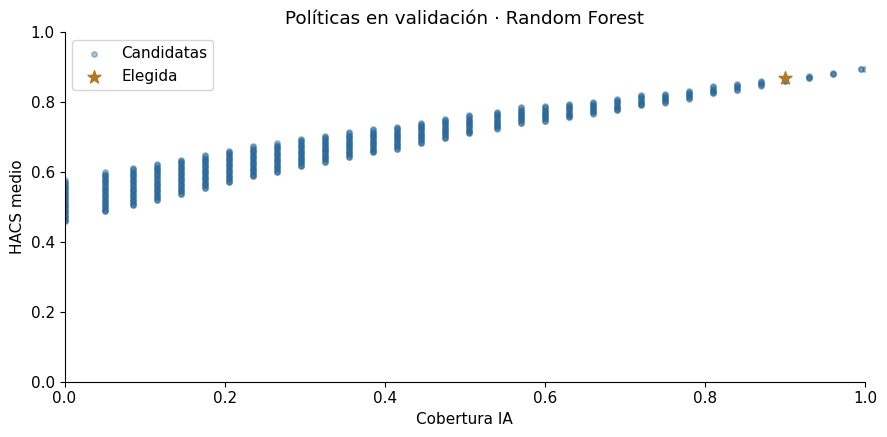

In [12]:
display(policy_table[["Modelo","Threshold","A","B","Junior","Senior","Coverage","HACS","Finalista"]].round(4))
selected_grid = search[search.Modelo==best_name]
fig,ax = plt.subplots(figsize=(9,4.5))
ax.scatter(selected_grid.Coverage,selected_grid.HACS,s=15,alpha=0.4,color=COLORS["IA"],label="Candidatas")
ax.scatter([chosen["Coverage"]],[chosen["HACS"]],s=95,marker="*",color=COLORS["Humano–IA"],label="Elegida")
ax.set(xlabel="Cobertura IA",ylabel="HACS medio",title=f"Políticas en validación · {best_name}",xlim=(0,1),ylim=(0,1))
ax.legend()
savefig("04_politicas_validacion.png")

### Evaluación de prueba — tres finalistas congelados

Se reporta la réplica 0, con semilla fijada, y 1,000 réplicas nuevas. La mejora
estricta >0.01 se comprueba en la realización y en la media Monte Carlo. Si un
modelo falla el requisito, se etiqueta como incumplimiento; no se cambia por un
cuarto modelo mirando prueba. La tabla de cada finalista incluye F1 de ambas clases,
coste, cobertura, humanos usados y fracción de réplicas con mejora >1 punto.

In [13]:
jtest,stest = simulate_analysts(ye,N_TEST_SIM,seed=20261104)
final_rows,sim_rows,decision_frames,base_rows = [],[],[],[]
for name in finalist_names:
    prob = fitted[name].predict_proba(X.iloc[idx_test])[:,1]
    test_prob[name] = prob
    ai,u = (prob>=thresholds_cls[name]).astype(int),entropy(prob)
    policy = policies[name]
    makers = route(u,policy["A"],policy["B"])
    decisions = collaborate(ai,makers,jtest,stest).astype(int)
    coverage = float(np.mean(makers=="IA"))
    efficiency = float(1-np.mean(makers!="IA"))
    fm = f1_many(ye,decisions)
    base,point = metrics(ye,ai,prob),metrics(ye,decisions[0])
    base_rows.append({"Modelo":name,"Threshold":thresholds_cls[name],**base,"Brier":brier_score_loss(ye,prob)})
    delta = point["F1"]-base["F1"]
    row = {"Grupo":GROUP,"Modelo":name,"F1 - Sólo IA":base["F1"],"F1 - IA + Human":point["F1"],
        "Mejora":delta,"Mejora_pp":100*delta,"Mejora_relativa_pct":100*delta/base["F1"],
        "HACS":.6*point["F1"]+.2*coverage+.2*efficiency,"Coverage":coverage,"Efficiency":efficiency,
        "N_IA":int(sum(makers=="IA")),"N_Junior":int(sum(makers=="Junior")),"N_Senior":int(sum(makers=="Senior")),
        "F1_bad_IA":base["F1_bad"],"F1_bad_colab":point["F1_bad"],
        "F1_colab_MC_mean":float(fm.mean()),"F1_colab_MC_p025":float(np.quantile(fm,.025)),
        "F1_colab_MC_p975":float(np.quantile(fm,.975)),"Mejora_MC_mean":float(fm.mean()-base["F1"]),
        "Prob_mejora_mayor_1pp_MC":float(np.mean(fm-base["F1"]>MIN_GAIN)),
        "HACS_MC_mean":float(.6*fm.mean()+.4*coverage),"Coste_IA":base["Coste"],"Coste_colab":point["Coste"],
        "Cumple_mayor_1pp":bool(delta>MIN_GAIN),"Cumple_MC_mayor_1pp":bool(fm.mean()-base["F1"]>MIN_GAIN),
        "Seleccionado_validacion":name==best_name}
    final_rows.append(row)
    sim_rows.extend({"Modelo":name,"replica":r,"F1":float(f),"Mejora":float(f-base["F1"]),
        "HACS":float(.6*f+.4*coverage)} for r,f in enumerate(fm))
    decision_frames.append(pd.DataFrame({"Modelo":name,"row_id":idx_test,"y_true":ye,"p_good":prob,
        "threshold":thresholds_cls[name],"entropy":u,"y_ai":ai,"responsable":makers,
        "y_junior":jtest[0],"y_senior":stest[0],"y_final":decisions[0]}))
results = pd.DataFrame(final_rows)
all_decisions = pd.concat(decision_frames,ignore_index=True)
all_decisions.to_csv(OUT/"decisiones_prueba.csv",index=False)
results.to_csv(OUT/"tabla_resultados.csv",index=False)
pd.DataFrame(sim_rows).to_csv(OUT/"simulaciones_prueba.csv",index=False)
pd.DataFrame(base_rows).to_csv(OUT/"modelos_prueba.csv",index=False)
display(results[["Modelo","F1 - Sólo IA","F1 - IA + Human","Mejora_pp","HACS","Coverage","Cumple_mayor_1pp"]].round(4))
display(results[["Modelo","F1_colab_MC_mean","Mejora_MC_mean","HACS_MC_mean","Prob_mejora_mayor_1pp_MC"]].round(4))
selected_decisions = all_decisions[all_decisions.Modelo==best_name].reset_index(drop=True)
selected_result = results[results.Modelo==best_name].iloc[0]
comparison = pd.DataFrame([
    {"Sistema":"IA",**metrics(ye,selected_decisions.y_ai,test_prob[best_name])},
    {"Sistema":"Junior",**metrics(ye,jtest[0])},
    {"Sistema":"Senior",**metrics(ye,stest[0])},
    {"Sistema":"Humano–IA",**metrics(ye,selected_decisions.y_final)}])
comparison.to_csv(OUT/"comparacion_sistemas.csv",index=False)
display(comparison[["Sistema","Accuracy","Precision","Recall","F1","F1_bad","Coste"]].round(4))

,Modelo,F1 - Sólo IA,F1 - IA + Human,Mejora_pp,HACS,Coverage,Cumple_mayor_1pp
0,Random Forest,0.8387,0.8638,2.5078,0.8863,0.92,True
1,CatBoost,0.8487,0.8805,3.1862,0.8883,0.90,True
2,XGBoost,0.8191,0.8660,4.6867,0.8676,0.87,True


,Modelo,F1_colab_MC_mean,Mejora_MC_mean,HACS_MC_mean,Prob_mejora_mayor_1pp_MC
0,Random Forest,0.8612,0.0225,0.8847,1.0
1,CatBoost,0.8802,0.0315,0.8881,1.0
2,XGBoost,0.8675,0.0483,0.8685,1.0


,Sistema,Accuracy,Precision,Recall,F1,F1_bad,Coste
0,IA,0.750,0.7647,0.9286,0.8387,0.4444,210
1,Junior,0.690,0.8482,0.6786,0.7540,0.5811,130
2,Senior,0.955,0.9852,0.9500,0.9673,0.9280,17
3,Humano–IA,0.795,0.8075,0.9286,0.8638,0.5859,165


### Matriz de confusión, ROC y comparación de sistemas

La ROC corresponde a probabilidades del modelo IA, positivo = buen crédito. El sistema colaborativo
entrega decisiones discretas, por lo que no inventamos una curva ROC a partir
de respuestas humanas. La matriz colaborativa permite revisar cambios en FP/FN
y reconciliar el coste. Las barras comparan la réplica reproducible, no las medias.

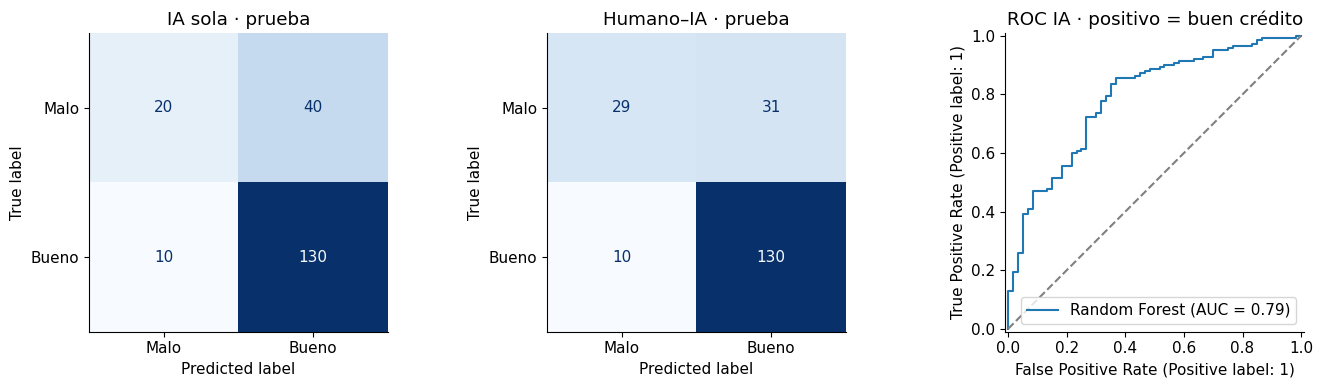

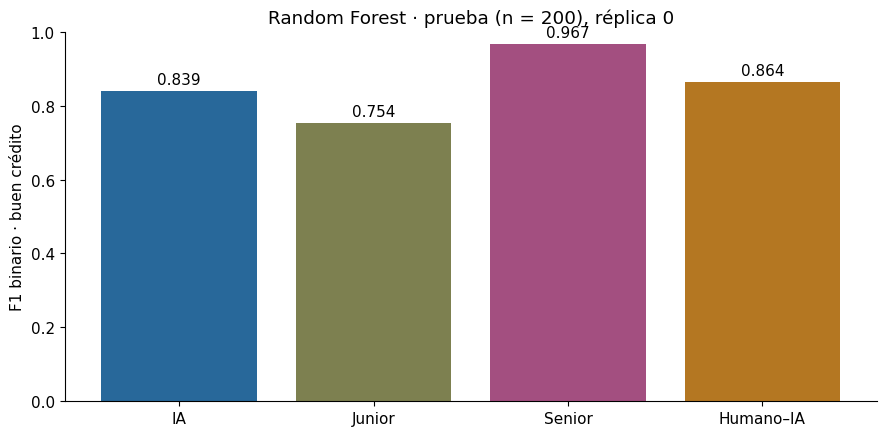

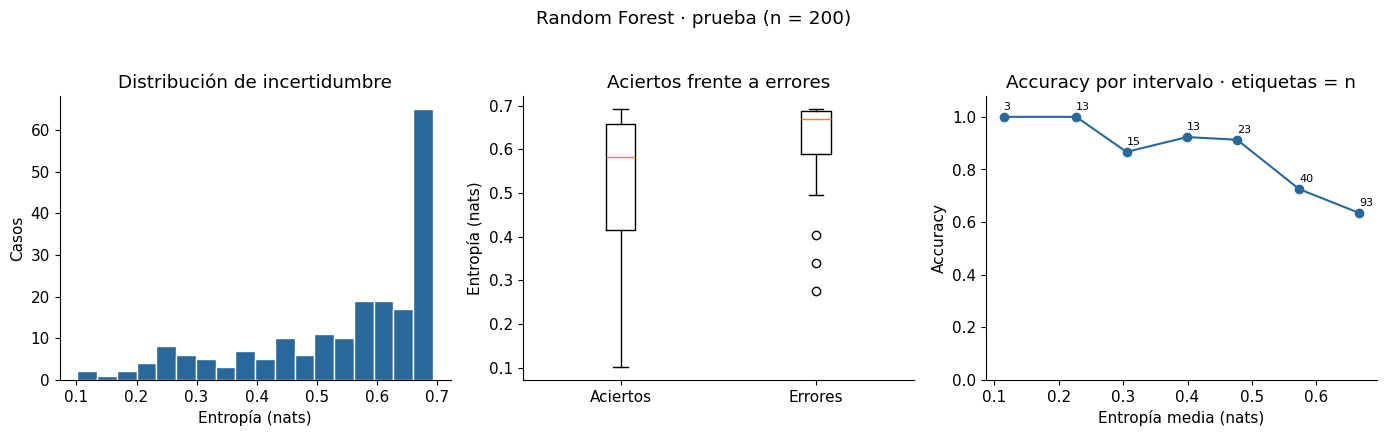

,Valor
split,prueba
mean_correct,0.517753
mean_error,0.625948
mann_whitney_p,0.0
error_detection_auc,0.738267


In [14]:
fig,axes = plt.subplots(1,3,figsize=(14,4))
ConfusionMatrixDisplay.from_predictions(ye,selected_decisions.y_ai,display_labels=["Malo","Bueno"],ax=axes[0],colorbar=False,cmap="Blues")
axes[0].set_title("IA sola · prueba")
ConfusionMatrixDisplay.from_predictions(ye,selected_decisions.y_final,display_labels=["Malo","Bueno"],ax=axes[1],colorbar=False,cmap="Blues")
axes[1].set_title("Humano–IA · prueba")
RocCurveDisplay.from_predictions(ye,test_prob[best_name],ax=axes[2],name=best_name)
axes[2].plot([0,1],[0,1],"--",color="gray")
axes[2].set_title("ROC IA · positivo = buen crédito")
savefig("05_evaluacion_prueba.png")
fig,ax = plt.subplots(figsize=(9,4.5))
bars = ax.bar(comparison.Sistema,comparison.F1,color=[COLORS[x] for x in comparison.Sistema])
ax.bar_label(bars,fmt="%.3f",padding=3)
ax.set(ylabel="F1 binario · buen crédito",ylim=(0,1),title=f"{best_name} · prueba (n = 200), réplica 0")
savefig("06_comparacion_sistemas.png")
uncertainty_stats.append(uncertainty_analysis(test_prob[best_name],ye,"prueba","07_incertidumbre_prueba.png"))
pd.DataFrame(uncertainty_stats).to_csv(OUT / "estadistica_incertidumbre.csv",index=False)

### Sensibilidad a la simulación y a la muestra de prueba

El histograma describe 1,000 respuestas humanas alternativas con igual política.
Además, un bootstrap pareado de solicitudes mantiene juntas las decisiones IA y
colaborativas de cada caso de la réplica 0. Su intervalo percentil es exploratorio:
no incluye el entrenamiento, la selección de umbrales ni la simulación humana
adicional. No es una prueba de mejora garantizada en futuros solicitantes.

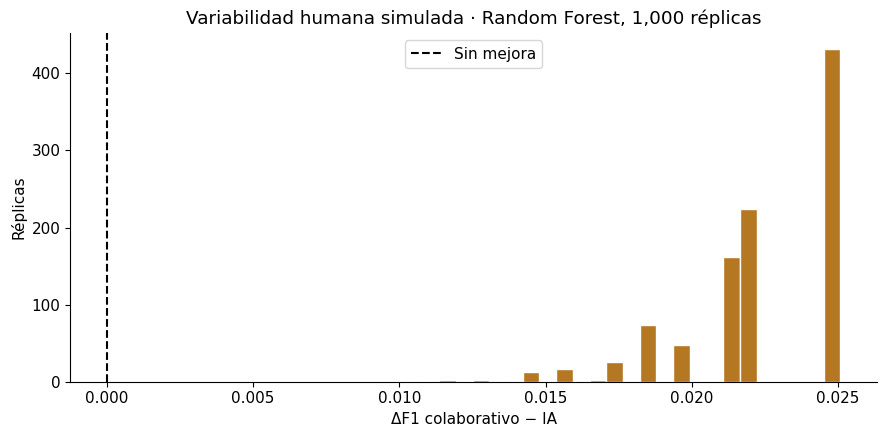

IC bootstrap pareado 95% de ΔF1 (réplica 0): [0.0108 0.0431]


In [15]:
rng = np.random.default_rng(903)
bootstrap_delta = []
ya = selected_decisions.y_ai.to_numpy()
yf = selected_decisions.y_final.to_numpy()
for _ in range(1000):
    ix = rng.integers(0,len(ye),len(ye))
    bootstrap_delta.append(f1_score(ye[ix],yf[ix],zero_division=0)-f1_score(ye[ix],ya[ix],zero_division=0))
ci = np.quantile(bootstrap_delta,[0.025,0.975])
pd.DataFrame({"delta_F1":bootstrap_delta}).to_csv(OUT / "bootstrap_mejora.csv",index=False)
sim = pd.DataFrame(sim_rows)
s = sim[sim.Modelo==best_name]
fig,ax = plt.subplots(figsize=(9,4.5))
ax.hist(s.Mejora,bins=25,color=COLORS["Humano–IA"],edgecolor="white")
ax.axvline(0,color="black",linestyle="--",label="Sin mejora")
ax.set(xlabel="ΔF1 colaborativo − IA",ylabel="Réplicas",title=f"Variabilidad humana simulada · {best_name}, 1,000 réplicas")
ax.legend()
savefig("08_variabilidad_humana.png")
print("IC bootstrap pareado 95% de ΔF1 (réplica 0):",np.round(ci,4))
checkpoint("test", test_repetitions=N_TEST_SIM, bootstrap_delta_ci=ci.tolist())

## Parte 5 — Explicabilidad (15%)

### Actividad 5.1 — SHAP del modelo seleccionado

Se explican las variables transformadas del mismo modelo evaluado. Para árboles
usamos TreeExplainer; para regresión logística, LinearExplainer con fondo sólo de
entrenamiento. Se normaliza la salida binaria para explicar **buen crédito**.
Comprobamos aditividad: valor base + suma SHAP reconstruye probabilidad (Random
Forest) o log-odds (boosting/regresión logística).

Las importancias globales se agrupan de vuelta a las 20 variables originales.
El resumen global usa prueba para **interpretación posterior**, sin ajustar modelo
ni política. SHAP es una atribución del modelo, no evidencia causal ni certificación
de justicia. Las dependencias entre atributos pueden repartir las atribuciones.

Documentación: [TreeExplainer](https://shap.readthedocs.io/en/latest/generated/shap.TreeExplainer.html)
y [LinearExplainer](https://shap.readthedocs.io/en/latest/generated/shap.LinearExplainer.html).

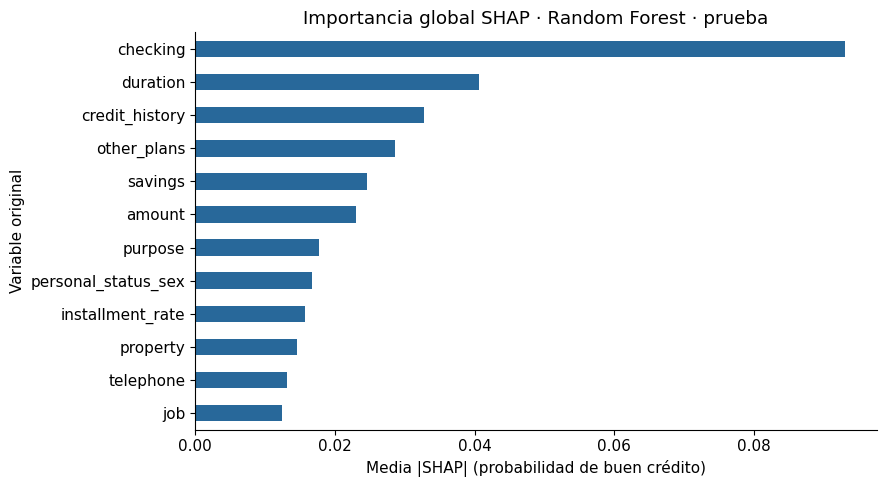

Error máximo de aditividad SHAP: 1.2212453270876722e-15 | Unidades: probabilidad de buen crédito


In [16]:
if best_name == "Logistic Regression":
    explainer = shap.LinearExplainer(best_model,Ztrain)
    explanation = explainer(Ztest)
    units = "log-odds de buen crédito"
else:
    explainer = shap.TreeExplainer(best_model)
    explanation = explainer(Ztest)
    units = "probabilidad de buen crédito" if best_name=="Random Forest" else "log-odds de buen crédito"
values,base = np.asarray(explanation.values),np.asarray(explanation.base_values)
if values.ndim==3:
    values = values[:,:,1]
    base = base[:,1]
if base.ndim==0:
    base = np.full(len(ye),float(base))
reconstructed = base + values.sum(axis=1)
p = test_prob[best_name]
expected = p if best_name=="Random Forest" else np.log(np.clip(p,1e-10,1-1e-10)/(1-np.clip(p,1e-10,1-1e-10)))
additivity_error = float(np.max(np.abs(reconstructed-expected)))
assert np.allclose(reconstructed,expected,atol=1e-4), additivity_error
onehot = pre.named_transformers_["cat"].named_steps["onehot"]
source_features = NUM + [c for c,levels in zip(CAT,onehot.categories_) for _ in levels]
assert len(source_features)==values.shape[1]
aggregated = pd.DataFrame(values,columns=source_features).T.groupby(level=0,sort=False).sum().T
importance = aggregated.abs().mean().sort_values(ascending=False)
importance.rename("mean_abs_SHAP").to_csv(OUT / "shap_importancia_global.csv")
pd.DataFrame(values,columns=names).assign(row_id=idx_test).to_csv(OUT / "shap_valores.csv",index=False)
fig,ax = plt.subplots(figsize=(9,5))
importance.head(12).sort_values().plot.barh(ax=ax,color=COLORS["IA"])
ax.set(xlabel=f"Media |SHAP| ({units})",ylabel="Variable original",title=f"Importancia global SHAP · {best_name} · prueba")
savefig("09_shap_global.png")
print("Error máximo de aditividad SHAP:",additivity_error,"| Unidades:",units)

### Actividad 5.2 — Nueve casos de estudio

Seleccionamos tres aciertos entre las menores entropías, tres aciertos distintos
entre las mayores y tres errores. «Baja» y «alta» son relativas a los aciertos
observados, no garantizan pertenecer a zonas de enrutamiento; mostramos ambos.
La selección de casos es ilustrativa, posterior a la evaluación, y no modifica
decisiones. Si faltaran casos en un grupo, se registra la disponibilidad real.

,grupo,row_id,y_true,y_ai,p_good,entropy,responsable
0,Correcta / baja entropía,803,1,1,0.9790,0.1017,IA
1,Correcta / baja entropía,234,1,1,0.9783,0.1046,IA
2,Correcta / baja entropía,742,1,1,0.9691,0.1378,IA
3,Correcta / alta entropía,216,1,1,0.4894,0.6929,Senior
4,Correcta / alta entropía,992,1,1,0.5137,0.6928,Senior
5,Correcta / alta entropía,658,1,1,0.5154,0.6927,Senior
6,Incorrecta,182,0,1,0.5020,0.6931,Senior
7,Incorrecta,788,0,1,0.4950,0.6931,Senior
8,Incorrecta,938,0,1,0.5059,0.6931,Senior


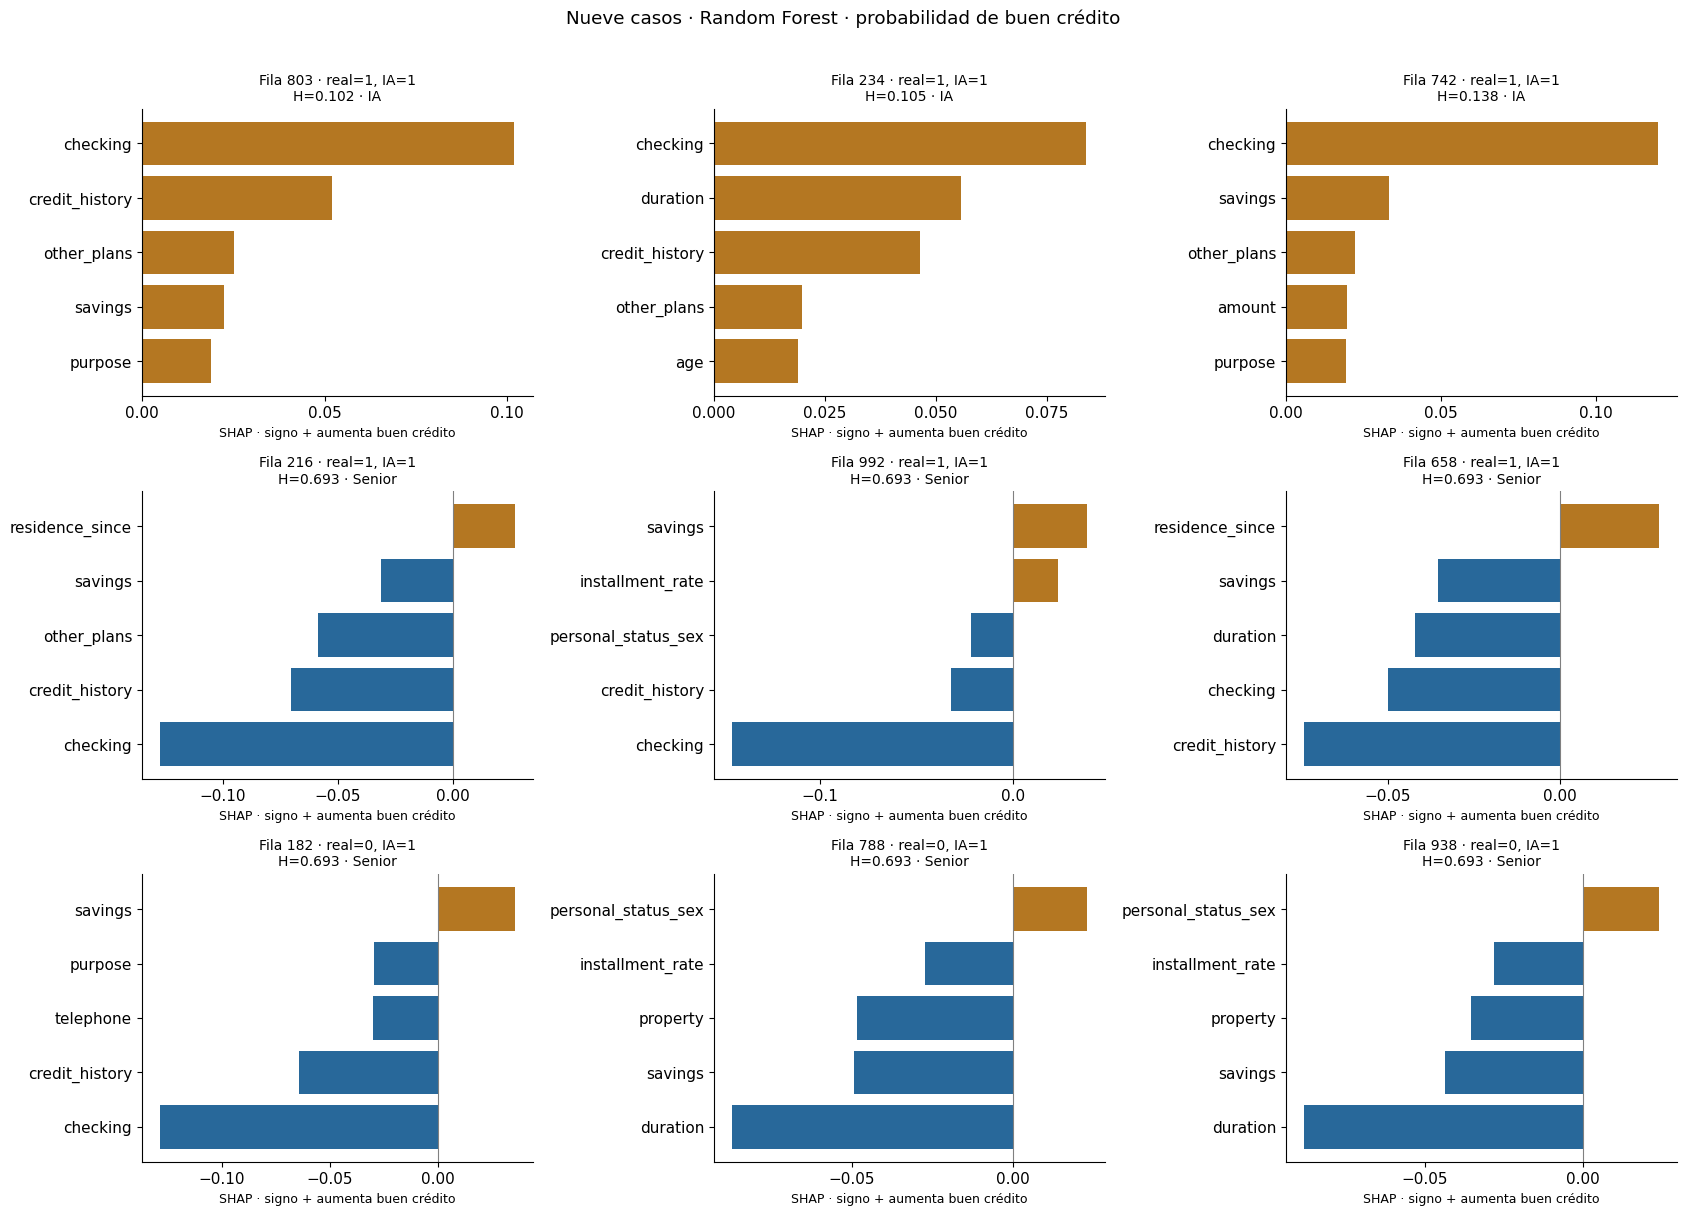

In [17]:
correct = selected_decisions.y_ai.to_numpy()==ye
u = selected_decisions.entropy.to_numpy()
correct_ids = np.flatnonzero(correct)
low = correct_ids[np.argsort(u[correct_ids])[:3]]
remaining = np.array([i for i in correct_ids if i not in low],dtype=int)
high = remaining[np.argsort(u[remaining])[-3:][::-1]]
errors = np.flatnonzero(~correct)
wrong = errors[np.argsort(u[errors])[-3:][::-1]]
case_groups = {"Correcta / baja entropía":low,"Correcta / alta entropía":high,"Incorrecta":wrong}
case_rows = []
for category,ids in case_groups.items():
    for i in ids:
        top = aggregated.iloc[i].abs().nlargest(3).index
        impacts = "; ".join(f"{f}={X.iloc[idx_test[i]][f]}: SHAP {aggregated.iloc[i][f]:+.3f}" for f in top)
        case_rows.append({"grupo":category,"pos_test":int(i),"row_id":int(idx_test[i]),"y_true":int(ye[i]),
            "y_ai":int(ya[i]),"p_good":float(p[i]),"entropy":float(u[i]),
            "responsable":selected_decisions.iloc[i].responsable,"impactos":impacts})
cases = pd.DataFrame(case_rows)
cases.to_csv(OUT / "casos_shap.csv",index=False)
display(cases[["grupo","row_id","y_true","y_ai","p_good","entropy","responsable"]].round(4))
fig,axes = plt.subplots(3,3,figsize=(17,12))
for ax,case in zip(axes.flat,cases.itertuples()):
    contributions = aggregated.iloc[case.pos_test]
    top = contributions.abs().nlargest(5).index
    v = contributions[top].sort_values()
    ax.barh(v.index,v.values,color=[COLORS["IA"] if z<0 else COLORS["Humano–IA"] for z in v.values])
    ax.axvline(0,color="gray",linewidth=0.8)
    ax.set_title(f"Fila {case.row_id} · real={case.y_true}, IA={case.y_ai}\nH={case.entropy:.3f} · {case.responsable}",fontsize=10)
    ax.set_xlabel("SHAP · signo + aumenta buen crédito",fontsize=9)
    ax.locator_params(axis="x",nbins=4)
for ax in list(axes.flat)[len(cases):]:
    ax.set_visible(False)
fig.suptitle(f"Nueve casos · {best_name} · {units}",y=1.01)
savefig("10_shap_casos.png")

### Actividad 5.3 — Interpretación de cada caso

En cada registro respondemos qué variables influyen, si el signo es coherente
con la salida del modelo, para qué puede servir la explicación y qué confianza
permite. «Coherente» significa consistencia interna, no una regla causal sobre
una persona. Una explicación de una predicción errónea puede ser matemáticamente
coherente y aun así exigir revisión. El simulador de humanos no utiliza SHAP;
por tanto, no atribuimos a SHAP el incremento de F1.

In [18]:
for case in cases.itertuples():
    outcome = "coincide con la etiqueta" if case.y_true==case.y_ai else "es incorrecta frente a la etiqueta"
    signed_sum = float(aggregated.iloc[case.pos_test].sum())
    display(Markdown(f"**Fila {case.row_id} — {case.grupo}.** "
        f"**Variables:** {case.impactos}. "
        f"**Coherencia:** la suma de contribuciones es {signed_sum:+.3f} en {units}; "
        f"junto al valor base reconstruye la salida (control de aditividad superado), pero la predicción {outcome}. "
        f"**Utilidad:** el analista puede contrastar estos atributos con documentos del solicitante; "
        f"el responsable asignado es {case.responsable}. "
        f"**Confianza o confusión:** H={case.entropy:.3f} describe incertidumbre del modelo, "
        f"no validez causal. Los códigos categóricos y atributos correlacionados requieren consultar "
        f"el diccionario; ni SHAP ni baja entropía garantizan una decisión correcta o equitativa."))

**Fila 803 — Correcta / baja entropía.** **Variables:** checking=A14: SHAP +0.102; credit_history=A34: SHAP +0.052; other_plans=A143: SHAP +0.025. **Coherencia:** la suma de contribuciones es +0.280 en probabilidad de buen crédito; junto al valor base reconstruye la salida (control de aditividad superado), pero la predicción coincide con la etiqueta. **Utilidad:** el analista puede contrastar estos atributos con documentos del solicitante; el responsable asignado es IA. **Confianza o confusión:** H=0.102 describe incertidumbre del modelo, no validez causal. Los códigos categóricos y atributos correlacionados requieren consultar el diccionario; ni SHAP ni baja entropía garantizan una decisión correcta o equitativa.

**Fila 234 — Correcta / baja entropía.** **Variables:** checking=A14: SHAP +0.084; duration=4: SHAP +0.056; credit_history=A34: SHAP +0.046. **Coherencia:** la suma de contribuciones es +0.279 en probabilidad de buen crédito; junto al valor base reconstruye la salida (control de aditividad superado), pero la predicción coincide con la etiqueta. **Utilidad:** el analista puede contrastar estos atributos con documentos del solicitante; el responsable asignado es IA. **Confianza o confusión:** H=0.105 describe incertidumbre del modelo, no validez causal. Los códigos categóricos y atributos correlacionados requieren consultar el diccionario; ni SHAP ni baja entropía garantizan una decisión correcta o equitativa.

**Fila 742 — Correcta / baja entropía.** **Variables:** checking=A14: SHAP +0.120; savings=A65: SHAP +0.033; other_plans=A143: SHAP +0.022. **Coherencia:** la suma de contribuciones es +0.270 en probabilidad de buen crédito; junto al valor base reconstruye la salida (control de aditividad superado), pero la predicción coincide con la etiqueta. **Utilidad:** el analista puede contrastar estos atributos con documentos del solicitante; el responsable asignado es IA. **Confianza o confusión:** H=0.138 describe incertidumbre del modelo, no validez causal. Los códigos categóricos y atributos correlacionados requieren consultar el diccionario; ni SHAP ni baja entropía garantizan una decisión correcta o equitativa.

**Fila 216 — Correcta / alta entropía.** **Variables:** checking=A11: SHAP -0.127; credit_history=A30: SHAP -0.070; other_plans=A141: SHAP -0.058. **Coherencia:** la suma de contribuciones es -0.210 en probabilidad de buen crédito; junto al valor base reconstruye la salida (control de aditividad superado), pero la predicción coincide con la etiqueta. **Utilidad:** el analista puede contrastar estos atributos con documentos del solicitante; el responsable asignado es Senior. **Confianza o confusión:** H=0.693 describe incertidumbre del modelo, no validez causal. Los códigos categóricos y atributos correlacionados requieren consultar el diccionario; ni SHAP ni baja entropía garantizan una decisión correcta o equitativa.

**Fila 992 — Correcta / alta entropía.** **Variables:** checking=A11: SHAP -0.146; savings=A65: SHAP +0.039; credit_history=A32: SHAP -0.032. **Coherencia:** la suma de contribuciones es -0.186 en probabilidad de buen crédito; junto al valor base reconstruye la salida (control de aditividad superado), pero la predicción coincide con la etiqueta. **Utilidad:** el analista puede contrastar estos atributos con documentos del solicitante; el responsable asignado es Senior. **Confianza o confusión:** H=0.693 describe incertidumbre del modelo, no validez causal. Los códigos categóricos y atributos correlacionados requieren consultar el diccionario; ni SHAP ni baja entropía garantizan una decisión correcta o equitativa.

**Fila 658 — Correcta / alta entropía.** **Variables:** credit_history=A30: SHAP -0.074; checking=A12: SHAP -0.050; duration=30: SHAP -0.042. **Coherencia:** la suma de contribuciones es -0.184 en probabilidad de buen crédito; junto al valor base reconstruye la salida (control de aditividad superado), pero la predicción coincide con la etiqueta. **Utilidad:** el analista puede contrastar estos atributos con documentos del solicitante; el responsable asignado es Senior. **Confianza o confusión:** H=0.693 describe incertidumbre del modelo, no validez causal. Los códigos categóricos y atributos correlacionados requieren consultar el diccionario; ni SHAP ni baja entropía garantizan una decisión correcta o equitativa.

**Fila 182 — Incorrecta.** **Variables:** checking=A11: SHAP -0.129; credit_history=A31: SHAP -0.064; savings=A65: SHAP +0.036. **Coherencia:** la suma de contribuciones es -0.197 en probabilidad de buen crédito; junto al valor base reconstruye la salida (control de aditividad superado), pero la predicción es incorrecta frente a la etiqueta. **Utilidad:** el analista puede contrastar estos atributos con documentos del solicitante; el responsable asignado es Senior. **Confianza o confusión:** H=0.693 describe incertidumbre del modelo, no validez causal. Los códigos categóricos y atributos correlacionados requieren consultar el diccionario; ni SHAP ni baja entropía garantizan una decisión correcta o equitativa.

**Fila 788 — Incorrecta.** **Variables:** duration=48: SHAP -0.087; savings=A61: SHAP -0.049; property=A124: SHAP -0.048. **Coherencia:** la suma de contribuciones es -0.204 en probabilidad de buen crédito; junto al valor base reconstruye la salida (control de aditividad superado), pero la predicción es incorrecta frente a la etiqueta. **Utilidad:** el analista puede contrastar estos atributos con documentos del solicitante; el responsable asignado es Senior. **Confianza o confusión:** H=0.693 describe incertidumbre del modelo, no validez causal. Los códigos categóricos y atributos correlacionados requieren consultar el diccionario; ni SHAP ni baja entropía garantizan una decisión correcta o equitativa.

**Fila 938 — Incorrecta.** **Variables:** duration=60: SHAP -0.088; savings=A61: SHAP -0.043; property=A124: SHAP -0.035. **Coherencia:** la suma de contribuciones es -0.193 en probabilidad de buen crédito; junto al valor base reconstruye la salida (control de aditividad superado), pero la predicción es incorrecta frente a la etiqueta. **Utilidad:** el analista puede contrastar estos atributos con documentos del solicitante; el responsable asignado es Senior. **Confianza o confusión:** H=0.693 describe incertidumbre del modelo, no validez causal. Los códigos categóricos y atributos correlacionados requieren consultar el diccionario; ni SHAP ni baja entropía garantizan una decisión correcta o equitativa.

## Parte 6 — Puntaje final HACS (10%)

### Actividad 6.1 — Optimización y requisito estricto

Se seleccionaron modelo y política por HACS de validación, con margen preventivo
de mejora. Las decisiones se congelaron antes de prueba. Para el requisito del
usuario se comprueba $\Delta F1>0.01$; una diferencia exactamente 0.01 no alcanza.

$Coverage=N_{IA}/N$, $Efficiency=1-N_{humanos}/N$ y
$HACS=0.6F1_{colab}+0.2Coverage+0.2Efficiency$.

Cobertura y eficiencia coinciden. El HACS se mantiene idéntico al PDF; no se
añaden bonificaciones por superar 0.9 ni se penaliza distinto al senior.

### Actividad 6.2 — Tabla de entrega y defensa

«Mejora» es diferencia absoluta de F1; «Mejora_pp» la expresa en puntos
porcentuales. La comparación histórica debe usar la misma clase positiva:
un HACS mayor tras invertir la etiqueta no demuestra por sí solo un modelo mejor.

In [19]:
ranking_cols = ["Grupo","Modelo","F1 - Sólo IA","F1 - IA + Human","Mejora","HACS"]
results[ranking_cols].to_csv(OUT/"tabla_entrega.csv",index=False)
display(results[ranking_cols].round(4))
r = selected_result
st = uncertainty_stats[-1]
val_selected = validation[validation.Modelo==best_name].iloc[0]
discussion = f"""### Modelo defendido: {best_name}

Elegido por HACS medio de validación **{chosen['HACS']:.4f}**, entre cinco familias.
Umbral de clasificación aprendido con OOF = **{thresholds_cls[best_name]:.3f}**;
política de entropía A={chosen['A']:.4f}, B={chosen['B']:.4f} nats.
En validación, mejora media={chosen['Mejora']:.4f} y percentil 10 de mejora={chosen['Delta_p10']:.4f}.

En prueba: F1 de buen crédito IA **{r['F1 - Sólo IA']:.4f}**, colaborativo
**{r['F1 - IA + Human']:.4f}**, mejora **{r['Mejora_pp']:+.2f} puntos porcentuales**
({r['Mejora_relativa_pct']:+.2f}% relativo) y HACS **{r['HACS']:.4f}**.
Cumple mejora estricta >0.01 en réplica reportada: **{r['Cumple_mayor_1pp']}**;
en media Monte Carlo: **{r['Cumple_MC_mayor_1pp']}**.

Decisiones: {r['N_IA']} IA, {r['N_Junior']} junior y {r['N_Senior']} senior;
cobertura={r['Coverage']:.1%}. Coste original 5 FP + FN: IA **{r['Coste_IA']}**,
colaborativo **{r['Coste_colab']}**. F1 de mal crédito: IA {r['F1_bad_IA']:.4f},
colaborativo {r['F1_bad_colab']:.4f}; no se oculta el comportamiento de la otra clase.

En 1,000 réplicas: F1 colaborativo medio **{r['F1_colab_MC_mean']:.4f}**,
intervalo Monte Carlo central 95% [{r['F1_colab_MC_p025']:.4f},{r['F1_colab_MC_p975']:.4f}],
HACS medio **{r['HACS_MC_mean']:.4f}** y mejora >1 punto en **{r['Prob_mejora_mayor_1pp_MC']:.1%}**
de réplicas. IC bootstrap pareado de mejora, réplica 0: [{ci[0]:.4f},{ci[1]:.4f}].

Entropía media: aciertos {st['mean_correct']:.4f}, errores {st['mean_error']:.4f};
AUC de detección de errores {st['error_detection_auc']:.4f}. No toda certeza acierta.

**Límites:** accuracies junior/senior son supuestos pedagógicos; no representan
evidencia humana real. SHAP explica el clasificador, no mejora al simulador ni
demuestra causalidad. No medimos fatiga, dependencia humano–IA, coste laboral ni
equidad por grupos. Los umbrales de colaboración se buscan sobre sólo 200 casos
de validación y pueden sobreajustar. Prueba ya se vio en v1; se necesita un
conjunto externo y un experimento humano para sostener beneficios operativos.
El cambio de F1 de malo a bueno altera la escala de comparación con v1.
"""
display(Markdown(discussion))
(OUT/"discusion_resultados.md").write_text(discussion,encoding="utf-8")

,Grupo,Modelo,F1 - Sólo IA,F1 - IA + Human,Mejora,HACS
0,Equipo por completar,Random Forest,0.8387,0.8638,0.0251,0.8863
1,Equipo por completar,CatBoost,0.8487,0.8805,0.0319,0.8883
2,Equipo por completar,XGBoost,0.8191,0.8660,0.0469,0.8676


### Modelo defendido: Random Forest

Elegido por HACS medio de validación **0.8696**, entre cinco familias.
Umbral de clasificación aprendido con OOF = **0.470**;
política de entropía A=0.6897, B=0.6897 nats.
En validación, mejora media=0.0239 y percentil 10 de mejora=0.0195.

En prueba: F1 de buen crédito IA **0.8387**, colaborativo
**0.8638**, mejora **+2.51 puntos porcentuales**
(+2.99% relativo) y HACS **0.8863**.
Cumple mejora estricta >0.01 en réplica reportada: **True**;
en media Monte Carlo: **True**.

Decisiones: 184 IA, 0 junior y 16 senior;
cobertura=92.0%. Coste original 5 FP + FN: IA **210**,
colaborativo **165**. F1 de mal crédito: IA 0.4444,
colaborativo 0.5859; no se oculta el comportamiento de la otra clase.

En 1,000 réplicas: F1 colaborativo medio **0.8612**,
intervalo Monte Carlo central 95% [0.8543,0.8638],
HACS medio **0.8847** y mejora >1 punto en **100.0%**
de réplicas. IC bootstrap pareado de mejora, réplica 0: [0.0108,0.0431].

Entropía media: aciertos 0.5178, errores 0.6259;
AUC de detección de errores 0.7383. No toda certeza acierta.

**Límites:** accuracies junior/senior son supuestos pedagógicos; no representan
evidencia humana real. SHAP explica el clasificador, no mejora al simulador ni
demuestra causalidad. No medimos fatiga, dependencia humano–IA, coste laboral ni
equidad por grupos. Los umbrales de colaboración se buscan sobre sólo 200 casos
de validación y pueden sobreajustar. Prueba ya se vio en v1; se necesita un
conjunto externo y un experimento humano para sostener beneficios operativos.
El cambio de F1 de malo a bueno altera la escala de comparación con v1.


1625

### Auditoría de fórmulas, trazabilidad y cierre

Las verificaciones reconcilian decisiones, etiquetas, F1 positivo bueno, coste,
HACS y mejora. El estado registra por separado si los tres finalistas cumplen
el requisito >1 punto; una ejecución técnicamente completa no oculta un fallo
experimental. Se guarda el pipeline completo y el umbral aprendido por finalista.

In [20]:
for row in results.to_dict("records"):
    d = all_decisions[all_decisions.Modelo==row["Modelo"]]
    assert len(d)==200 and d.row_id.nunique()==200
    assert np.array_equal(d.y_true,(df.iloc[d.row_id].original_class==1).astype(int))
    assert row["N_IA"]+row["N_Junior"]+row["N_Senior"]==200
    f_ai,f_final = f1_score(d.y_true,d.y_ai),f1_score(d.y_true,d.y_final)
    assert np.isclose(row["F1 - Sólo IA"],f_ai)
    assert np.isclose(row["F1 - IA + Human"],f_final)
    assert np.isclose(row["Mejora"],f_final-f_ai)
    assert row["Cumple_mayor_1pp"]==(f_final-f_ai>MIN_GAIN)
    assert np.isclose(row["HACS"],.6*f_final+.2*row["Coverage"]+.2*row["Efficiency"])
    joblib.dump({"pipeline":fitted[row["Modelo"]],"policy":policies[row["Modelo"]],
        "threshold":thresholds_cls[row["Modelo"]],"features":FEATURES,"positive_class":"good_credit"},
        OUT/(row["Modelo"].lower().replace(" ","_")+".joblib"))
manifest = [{"name":p.name,"bytes":p.stat().st_size,"sha256":hashlib.sha256(p.read_bytes()).hexdigest()}
    for p in sorted(OUT.iterdir()) if p.is_file() and p.name not in {"manifest.json","run_summary.json","__notebook__.ipynb"}]
(OUT/"manifest.json").write_text(json.dumps(manifest,indent=2),encoding="utf-8")
checkpoint("done",status="complete",selected_model=best_name,finalists=finalist_names,
    all_three_gain_gt_1pp=bool(results.Cumple_mayor_1pp.all()),
    all_three_mean_gain_gt_1pp=bool(results.Cumple_MC_mayor_1pp.all()),
    selected_test={k:(v.item() if isinstance(v,np.generic) else v) for k,v in r.to_dict().items()},
    shap_additivity_max_error=additivity_error,bootstrap_delta_ci=ci.tolist(),
    artifacts=[x["name"] for x in manifest])
print("Estado:",summary["status"],"| Etapa:",summary["stage"],"| Finalistas:",finalist_names)
print("Mejora >1pp, tres modelos:",summary["all_three_gain_gt_1pp"],"| Media MC:",summary["all_three_mean_gain_gt_1pp"])

Estado: complete | Etapa: done | Finalistas: ['Random Forest', 'CatBoost', 'XGBoost']
Mejora >1pp, tres modelos: True | Media MC: True
